In [1]:
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays, JSON
using Colors, Dates
using CSV
using Plots
using JuMP
using DataFrames
import DataFrames
import HiGHS
import StatsPlots
import Ipopt

# Generator definition
WindGenerator() = (
    variable_cost = 0.0,
)

wind_generator = WindGenerator()

generators = [
    (
        min = 0.0,
        max = 250.0,
        fixed_cost = 150.0,
        variable_cost = 1.0,
    ),
    (
        min = 0.0,
        max = 300.0,
        fixed_cost = 600.0,
        variable_cost = 1.0,
    ),
    (
        min = 0.0,
        max = 270.0,
        fixed_cost = 600.0,
        variable_cost = 1.0,
    )
]

function thermal_cost_function_1(g)
    return 0.11*g^2 + 5*g + 150
end

function thermal_cost_function_2(g)
    return 0.085*g^2 + 1.2*g + 600
end

function thermal_cost_function_3(g)
    return 0.1225*g^2 + g + 600
end

thermal_cost_functions = [
    thermal_cost_function_1,
    thermal_cost_function_2,
    thermal_cost_function_3
]

function extract_cost_coefficients(cost_function)
    c0 = cost_function(0.0)
    c1 = cost_function(1.0)
    c2 = cost_function(2.0)

    gamma = c0
    alpha = (c2 - 2c1 + c0) / 2
    beta = c1 - alpha - gamma

    return (alpha = alpha, beta = beta, gamma = gamma)
end

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)



In [2]:
# Non linear economic dispatch, second iteration
function solve_nonlinear_economic_dispatch(
    generators::Vector,
    wind,
    scenario;
    silent::Bool = true,
)
    N = 3

    # Quadratic cost coefficients: C_i(g) = a_i*g^2 + b_i*g + c_i
    a = [0.11, 0.085, 0.1225]
    b = [5.0, 1.2, 1.0]
    c = [150.0, 600.0, 600.0]

    # Effective objective coefficients, including variable_cost
    v = [generators[i].variable_cost for i in 1:N]
    A = v .* a
    B = v .* b

    # Net demand that must be supplied by thermal generators
    thermal_demand = scenario.demand - scenario.wind

    gmin = [generators[i].min for i in 1:N]
    gmax = [generators[i].max for i in 1:N]

    # Check feasibility
    if thermal_demand < sum(gmin) - 1e-8 ||
       thermal_demand > sum(gmax) + 1e-8
        error("Infeasible dispatch for this demand and wind scenario.")
    end

    # Handle demand at the extreme feasible limits
    if abs(thermal_demand - sum(gmin)) < 1e-10
        g_value = copy(gmin)
    elseif abs(thermal_demand - sum(gmax)) < 1e-10
        g_value = copy(gmax)
    else
        # Marginal costs at the generator limits
        lambda_low = minimum(2A[i] * gmin[i] + B[i] for i in 1:N)
        lambda_high = maximum(2A[i] * gmax[i] + B[i] for i in 1:N)

        # Bisection on the common marginal cost
        for _ in 1:80
            lambda = (lambda_low + lambda_high) / 2

            g_trial = [
                clamp(
                    (lambda - B[i]) / (2A[i]),
                    gmin[i],
                    gmax[i]
                )
                for i in 1:N
            ]

            if sum(g_trial) < thermal_demand
                lambda_low = lambda
            else
                lambda_high = lambda
            end
        end

        lambda = (lambda_low + lambda_high) / 2

        g_value = [
            clamp(
                (lambda - B[i]) / (2A[i]),
                gmin[i],
                gmax[i]
            )
            for i in 1:N
        ]

        # Correct any remaining floating-point power imbalance
        residual = thermal_demand - sum(g_value)

        for i in 1:N
            adjustment = clamp(
                residual,
                gmin[i] - g_value[i],
                gmax[i] - g_value[i]
            )
            g_value[i] += adjustment
            residual -= adjustment

            if abs(residual) < 1e-10
                break
            end
        end
    end

    w_value = scenario.wind

    # Total thermal generation cost
    total_cost = sum(
        v[i] * (a[i] * g_value[i]^2 +
                b[i] * g_value[i] + c[i])
        for i in 1:N
    )

    # Identify an unconstrained marginal generator
    marginal_generator = nothing
    market_price = nothing
    alpha = nothing
    beta = nothing

    for i in 1:N
        if (
            g_value[i] > gmin[i] + 1e-5 &&
            g_value[i] < gmax[i] - 1e-5
        )
            marginal_generator = i
            market_price = v[i] * (2a[i] * g_value[i] + b[i])

            alpha = a[i]
            beta = b[i]

            break
        end
    end

    wind_revenue = isnothing(market_price) ?
        nothing : market_price * w_value

    return (
        g = g_value,
        w = w_value,
        market_price = market_price,
        wind_revenue = wind_revenue,
        wind_cost = 0.0,
        total_cost = total_cost,
        marginal_generator = marginal_generator,
        alpha = alpha,
        beta = beta
    )
end


solve_nonlinear_economic_dispatch (generic function with 1 method)

In [3]:
function solve_realtime_dispatch(
    projected_wind,
    wind_regulation,
    up_regulation_factor,
    down_regulation_factor,
    alpha,
    beta;
    silent::Bool = true,
)
    P_up = max(wind_regulation, 0.0)
    P_down = max(-wind_regulation, 0.0)

    actual_wind = projected_wind + P_up - P_down

    regulation_cost =
        up_regulation_factor * beta * P_up +
        down_regulation_factor * beta * P_down

    cost = 0.5 * alpha * actual_wind^2 + regulation_cost

    return (
        actual_wind = actual_wind,
        P_up = P_up,
        P_down = P_down,
        regulation_cost = regulation_cost,
        c = cost,
    )
end

function Scenario(demand::Real, wind::Real)
    return (demand = demand, wind = wind)
end

Scenario (generic function with 1 method)

In [9]:

# Read and combine all three locations
data1 = CSV.read("Location1.csv", DataFrame)
data2 = CSV.read("Location2.csv", DataFrame)
data3 = CSV.read("Location3.csv", DataFrame)

data1.LocationID .= 1
data2.LocationID .= 2
data3.LocationID .= 3

data = vcat(data1, data2, data3)

# Convert timestamps and sort chronologically by location
data.Time = DateTime.(data.Time)
sort!(data, [:LocationID, :Time])

# Extract model inputs and target
n = nrow(data)
t = Float64.(data.Power)
wind10_raw = Float64.(data.windspeed_10m)
wind100_raw = Float64.(data.windspeed_100m)
gust10_raw = Float64.(data.windgusts_10m)
time = data.Time
location_id = data.LocationID

# Normalize wind parameters
x10 = wind10_raw ./ 10.0
x100 = wind100_raw ./ 10.0
xgust = gust10_raw ./ 10.0

# Extract time-based features (kept unchanged)
hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

# Parameters
α = 0.001
iter_max = 25000
λ = 0.01
reg_type = "l2"
δ = 1e-4

# RBF centers and feature matrix
c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

φ(x, j) = exp(-(γ * abs(x - c[j]))^2)

# Include all three wind parameters in the RBF feature matrix
Φ = [
    φ(x10[i], j) + φ(x100[i], j) + φ(xgust[i], j)
    for i in 1:n, j in 1:num_centers
]

Random.seed!(128)
θ = rand(num_centers + 1)


24-element Vector{Float64}:
 0.7782600985452837
 0.5108799400139158
 0.22834600401242877
 0.10222267743392721
 0.1675895154870558
 0.9240826465389811
 0.5070020964479707
 0.4639585763082237
 0.9848034870646215
 0.1534397314419771
 0.44304914302619913
 0.3405349224366424
 0.7111696733665324
 0.04286133206257037
 0.2450098757288347
 0.7005176116516865
 0.18634871096607653
 0.5514101214974481
 0.2026186652698373
 0.5608427739699046
 0.536482866605312
 0.7614784456926231
 0.19715077776729883
 0.03737476203190615

In [ ]:
# Prediction with more features, no time correlation
# Regulation weights
beta_up_weight = 1
beta_down_weight = 1

# Regulation cost from one sample
function sample_regulation_cost(θ, i)
    w_0 = θ[1]
    w = θ[2:end]

    z = w_0 + dot(Φ[i, :], w)
    y_hat = 1.0 / (1.0 + exp(-z))
    actual_power = t[i] * 50.0
    predicted_power = y_hat * 50.0

    da = solve_nonlinear_economic_dispatch(
        generators, wind_generator,
        Scenario(600.0, predicted_power)
    )

    # Difference between actual wind and scheduled wind
    wind_regulation = actual_power - da.w

    rt = solve_realtime_dispatch(
        da.w, wind_regulation,
        beta_up_weight, beta_down_weight,
        da.alpha, da.beta
    )

    # Minimize regulation cost, not day-ahead profit
    return rt.regulation_cost
end

# Single-sample loss for SGD
function sample_loss(θ, i)
    w = θ[2:end]
    loss = sample_regulation_cost(θ, i)

    if reg_type == "l2"
        loss += λ * sum(abs2, w)
    elseif reg_type == "l1"
        loss += λ * sum(abs, w)
    end

    return loss
end

# Full-dataset objective, used for evaluation
function regulation_loss(θ)
    mean_cost = mean(sample_regulation_cost(θ, i) for i in 1:n)
    w = θ[2:end]

    loss = mean_cost

    if reg_type == "l2"
        loss += λ * sum(abs2, w)
    elseif reg_type == "l1"
        loss += λ * sum(abs, w)
    end

    return loss
end

# Stochastic gradient descent using central finite differences
for iteration in 1:iter_max
    i = rand(1:n)
    gradient = zeros(length(θ))

    for j in eachindex(θ)
        θ_plus = copy(θ)
        θ_minus = copy(θ)

        θ_plus[j] += δ
        θ_minus[j] -= δ

        gradient[j] = (
            sample_loss(θ_plus, i) -
            sample_loss(θ_minus, i)
        ) / (2 * δ)
    end

    # Minimize the regulation-cost objective
    θ .-= α .* gradient
end

# Extract learned parameters
w_0 = θ[1]
w = θ[2:end]

# Final predictions and errors
prediction = clamp.(w_0 .+ Φ * w, 0.0, 1.0)
errors = prediction .- t

# Evaluate the full dataset after training
final_loss = regulation_loss(θ)
mean_regulation_cost = mean(
    sample_regulation_cost(θ, i) for i in 1:n
)

println()
println("Final regulation-cost objective: ", final_loss)
println("Mean squared prediction error: ", mean(abs2, errors))
println("Mean real-time regulation cost: ", mean_regulation_cost)



Final regulation-cost objective: 47.94328170340303
Mean squared prediction error: 0.14149116184774932
Mean real-time regulation cost: 47.92724941355933


In [4]:
function sigmoid(z)
    if z >= 0
        return 1.0 / (1.0 + exp(-z))
    else
        ez = exp(z)
        return ez / (1.0 + ez)
    end
end

# Load Location 4 as the unseen test location
test_data = CSV.read("Location4.csv", DataFrame)
test_data.Time = DateTime.(test_data.Time)
sort!(test_data, :Time)

# Find complete days containing 24 hourly observations
test_data.Date = Date.(test_data.Time)
daily_groups = groupby(test_data, :Date)

complete_days = [
    day for day in daily_groups
    if nrow(day) == 24 &&
       length(unique(day.Time)) == 24
]

if isempty(complete_days)
    error("Location 4 contains no days with exactly 24 unique hourly observations.")
end

# Select a random test day
Random.seed!(42)
test_day = complete_days[rand(1:length(complete_days))]
sort!(test_day, :Time)

println("Selected test day: ", test_day.Date[1])

# Actual normalized power and wind speed
t_test = Float64.(test_day.Power)
x_test = Float64.(test_day.windspeed_10m) ./ 10.0

# Construct the RBF feature matrix using the training centers
Φ_test = [
    exp(-(γ * abs(x_test[i] - c[j]))^2)
    for i in eachindex(x_test), j in eachindex(c)
]

# Predict power using the trained parameters
prediction_test = sigmoid.(w_0 .+ Φ_test * w)

# Convert normalized power to MW
actual_power = 50.0 .* t_test
predicted_power = 50.0 .* prediction_test

# Calculate hourly profit using the same dispatch functions as training
function calculate_test_profit(forecast_power, actual_power)
    da = solve_nonlinear_economic_dispatch(
        generators,
        wind_generator,
        Scenario(600.0, forecast_power)
    )

    wind_regulation = actual_power - da.w

    rt = solve_realtime_dispatch(
        da.w,
        wind_regulation,
        beta_up_weight,
        beta_down_weight,
        da.alpha,
        da.beta
    )

    return da.wind_revenue - rt.c
end

# Calculate predicted-forecast profit
predicted_profit = [
    calculate_test_profit(predicted_power[i], actual_power[i])
    for i in eachindex(actual_power)
]

# Calculate ideal-forecast profit
ideal_profit = [
    calculate_test_profit(actual_power[i], actual_power[i])
    for i in eachindex(actual_power)
]

# Calculate hourly difference between ideal and predicted profit
profit_difference = ideal_profit .- predicted_profit

# Plot predicted versus actual power
p1 = plot(
    test_day.Time,
    actual_power,
    label = "Actual Power",
    linewidth = 2,
    color = blue,
    xlabel = "Time",
    ylabel = "Power (MW)",
    title = "Location 4: Predicted vs Actual Power",
    legend = :best,
    xrotation = 30
)

plot!(
    p1,
    test_day.Time,
    predicted_power,
    label = "Predicted Power",
    linewidth = 2,
    linestyle = :dash,
    color = purple
)

# Plot profit difference versus time
p2 = plot(
    test_day.Time,
    profit_difference,
    label = "Ideal - Predicted Profit",
    linewidth = 2,
    marker = :circle,
    markersize = 4,
    color = purple,
    xlabel = "Time",
    ylabel = "Profit Difference",
    title = "Location 4: Ideal vs Predicted Profit Difference",
    legend = false,
    xrotation = 30
)

# Add horizontal reference line at zero
hline!(
    p2,
    [0],
    color = :black,
    linestyle = :dash,
    linewidth = 1,
    label = false
)

# Display both plots
plot(
    p1,
    p2,
    layout = grid(2, 1, heights = [0.45, 0.55]),
    size = (1100, 950),
    margin = 8Plots.mm
)


LoadError: InterruptException:

In [4]:

# Read and combine all three locations
data1 = CSV.read("Location1.csv", DataFrame)
data2 = CSV.read("Location2.csv", DataFrame)
data3 = CSV.read("Location3.csv", DataFrame)

data1.LocationID .= 1
data2.LocationID .= 2
data3.LocationID .= 3

data = vcat(data1, data2, data3)

# Convert timestamps and sort chronologically by location
data.Time = DateTime.(data.Time)
sort!(data, [:LocationID, :Time])

# Extract model inputs and target
n = nrow(data)
t = Float64.(data.Power)
wind10_raw = Float64.(data.windspeed_10m)
wind100_raw = Float64.(data.windspeed_100m)
gust10_raw = Float64.(data.windgusts_10m)
time = data.Time
location_id = data.LocationID

# Normalize wind parameters
x10 = wind10_raw ./ 10.0
x100 = wind100_raw ./ 10.0
xgust = gust10_raw ./ 10.0

# Extract time-based features
hour = Float64.(Dates.hour.(time))
hour_sin = sin.(2π .* hour ./ 24.0)
hour_cos = cos.(2π .* hour ./ 24.0)

# Parameters
α = 0.001
iter_max = 1000
λ = 0.01
reg_type = "l2"
δ = 1e-4

# RBF centers and feature matrix
c = collect(0.0:0.05:1.1)
num_centers = length(c)
γ = 5.0

φ(x, j) = exp(-(γ * abs(x - c[j]))^2)

Φ_weather = [
    φ(x10[i], j) + φ(x100[i], j) + φ(xgust[i], j)
    for i in 1:n, j in 1:num_centers
]

Φ_weather = hcat(Φ_weather, hour_sin, hour_cos)

day_groups = Dict{Int, Vector{UnitRange{Int}}}()

for loc in unique(location_id)
    loc_indices = findall(location_id .== loc)
    groups = UnitRange{Int}[]

    for k in 1:24:length(loc_indices)
        if k + 23 <= length(loc_indices)
            indices = loc_indices[k:k+23]

            # Require consecutive hourly timestamps
            if all(
                time[indices[j]] - time[indices[j-1]] == Hour(1)
                for j in 2:24
            )
                push!(groups, indices[1]:indices[end])
            end
        end
    end

    day_groups[loc] = groups
end

Random.seed!(128)
θ = zeros(size(Φ_weather, 2) + 4)


29-element Vector{Float64}:
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 ⋮
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0
 0.0

In [ ]:
# Prediction w/ time correlation
# Regulation weights
beta_up_weight = 1
beta_down_weight = 1

hours_per_day = 24
n_days = div(n, hours_per_day)

# CHANGED: Φ_weather must contain weather features only.
# θ contains: intercept, weather weights, and 2 lagged-power weights.
# t contains normalized power in chronological order.

# Regulation cost for one predicted sample
# CHANGED: Accept the predicted power directly
function sample_regulation_cost_from_prediction(predicted_power_norm, i)
    actual_power = t[i] * 50.0
    predicted_power = predicted_power_norm * 50.0

    da = solve_nonlinear_economic_dispatch(
        generators, wind_generator,
        Scenario(600.0, predicted_power)
    )

    # Difference between actual wind and scheduled wind
    wind_regulation = actual_power - da.w

    rt = solve_realtime_dispatch(
        da.w, wind_regulation,
        beta_up_weight, beta_down_weight,
        da.alpha, da.beta
    )

    return rt.regulation_cost
end


function predict_day(θ, day)
    first_i = (day - 1) * hours_per_day + 1
    last_i = day * hours_per_day

    predictions = zeros(hours_per_day)

    # Initialize with the previous day's actual power
    p_lag2 = t[first_i - 2]
    p_lag1 = t[first_i - 1]

    for (h, i) in enumerate(first_i:last_i)
        # Weather features + two lagged power values
        x = vcat(Φ_weather[i, :], p_lag1, p_lag2)

        z = θ[1] + dot(x, θ[2:end])
        p = 1.0 / (1.0 + exp(-z))

        predictions[h] = p

        p_lag2 = p_lag1
        p_lag1 = p
    end

    return predictions
end


# CHANGED: Loss over an entire recursively predicted day
function day_loss(θ, day)
    first_i = (day - 1) * hours_per_day + 1
    last_i = day * hours_per_day

    predictions = predict_day(θ, day)

    mean_cost = mean(
        sample_regulation_cost_from_prediction(predictions[h], i)
        for (h, i) in enumerate(first_i:last_i)
    )

    # Existing parameter regularization
    w = θ[2:end]

    if reg_type == "l2"
        mean_cost += λ * sum(abs2, w)
    elseif reg_type == "l1"
        mean_cost += λ * sum(abs, w)
    end

    return mean_cost
end

# CHANGED: Full-dataset objective evaluates complete days
# Day 1 is used as historical input for forecasting day 2.
function regulation_loss(θ)
    return mean(day_loss(θ, day) for day in 2:n_days)
end

# CHANGED: SGD selects a day instead of an individual sample
for iteration in 1:iter_max
    day = rand(2:n_days)
    gradient = zeros(length(θ))

    for j in eachindex(θ)
        θ_plus = copy(θ)
        θ_minus = copy(θ)

        θ_plus[j] += δ
        θ_minus[j] -= δ

        gradient[j] = (
            day_loss(θ_plus, day) -
            day_loss(θ_minus, day)
        ) / (2 * δ)
    end

    # Minimize the regulation-cost objective
    θ .-= α .* gradient
end

# Extract learned parameters
w_0 = θ[1]
w = θ[2:end]

# CHANGED: Generate recursive predictions for complete days
# First day supplies the historical power values.
prediction = fill(NaN, n)

for day in 2:n_days
    first_i = (day - 1) * hours_per_day + 1
    last_i = day * hours_per_day

    prediction[first_i:last_i] = predict_day(θ, day)
end

# Evaluate only samples with generated predictions
valid = .!isnan.(prediction)
errors = prediction[valid] .- t[valid]

# Evaluate the full dataset after training
final_loss = regulation_loss(θ)

mean_regulation_cost = mean(
    sample_regulation_cost_from_prediction(prediction[i], i)
    for i in findall(valid)
)

println()
println("Final regulation-cost objective: ", final_loss)
println("Mean squared prediction error: ", mean(abs2, errors))
println("Mean real-time regulation cost: ", mean_regulation_cost)


In [5]:
# Prediction w/ time correlation, emphasis on previous measurements
# Regulation weights
beta_up_weight = 0.8
beta_down_weight = 1.2

hours_per_day = 24
n_days = div(n, hours_per_day)


# Regulation cost for one predicted sample
function sample_regulation_cost_from_prediction(predicted_power_norm, i)
    actual_power = t[i] * 50.0
    predicted_power = predicted_power_norm * 50.0

    da = solve_nonlinear_economic_dispatch(
        generators, wind_generator,
        Scenario(600.0, predicted_power)
    )

    # Difference between actual wind and scheduled wind
    wind_regulation = actual_power - da.w

    rt = solve_realtime_dispatch(
        da.w, wind_regulation,
        beta_up_weight, beta_down_weight,
        da.alpha, da.beta
    )

    return rt.regulation_cost
end


function predict_day(θ, day)
    first_i = (day - 1) * hours_per_day + 1
    last_i = day * hours_per_day

    predictions = zeros(hours_per_day)

    # Initialize using the previous day's actual power
    p_lag2 = t[first_i - 2]
    p_lag1 = t[first_i - 1]

    # Previous hourly power change
    delta_p_lag1 = p_lag1 - p_lag2

    for (h, i) in enumerate(first_i:last_i)
        # Weather features + two lagged power levels
        # + previous power change
        x = vcat(
            Φ_weather[i, :],
            p_lag1,
            p_lag2,
            delta_p_lag1
        )

        z = θ[1] + dot(x, θ[2:end])
        p = 1.0 / (1.0 + exp(-z))

        predictions[h] = p

        # Update historical values recursively
        p_lag2 = p_lag1
        p_lag1 = p
        delta_p_lag1 = p_lag1 - p_lag2
    end

    return predictions
end

function day_loss(θ, day)
    first_i = (day - 1) * hours_per_day + 1
    last_i = day * hours_per_day

    predictions = predict_day(θ, day)

    mean_cost = mean(
        sample_regulation_cost_from_prediction(predictions[h], i)
        for (h, i) in enumerate(first_i:last_i)
    )

    # Existing parameter regularization
    w = θ[2:end]

    if reg_type == "l2"
        mean_cost += λ * sum(abs2, w)
    elseif reg_type == "l1"
        mean_cost += λ * sum(abs, w)
    end

    return mean_cost
end

# Day 1 is used as historical input for forecasting day 2.
function regulation_loss(θ)
    return mean(day_loss(θ, day) for day in 2:n_days)
end


for iteration in 1:iter_max
    day = rand(2:n_days)
    gradient = zeros(length(θ))

    for j in eachindex(θ)
        θ_plus = copy(θ)
        θ_minus = copy(θ)

        θ_plus[j] += δ
        θ_minus[j] -= δ

        gradient[j] = (
            day_loss(θ_plus, day) -
            day_loss(θ_minus, day)
        ) / (2 * δ)
    end

    # Minimize the regulation-cost objective
    θ .-= α .* gradient
end

# Extract learned parameters
w_0 = θ[1]
w = θ[2:end]

# First day supplies the historical power values.
prediction = fill(NaN, n)

for day in 2:n_days
    first_i = (day - 1) * hours_per_day + 1
    last_i = day * hours_per_day

    prediction[first_i:last_i] = predict_day(θ, day)
end

# Evaluate only samples with generated predictions
valid = .!isnan.(prediction)
errors = prediction[valid] .- t[valid]

# Evaluate the full dataset after training
final_loss = regulation_loss(θ)

mean_regulation_cost = mean(
    sample_regulation_cost_from_prediction(prediction[i], i)
    for i in findall(valid)
)

println()
println("Final regulation-cost objective: ", final_loss)
println("Mean squared prediction error: ", mean(abs2, errors))
println("Mean real-time regulation cost: ", mean_regulation_cost)



Final regulation-cost objective: 42.96625947601934
Mean squared prediction error: 0.07617682266558765
Mean real-time regulation cost: 42.9539721818427


Selected test day: 2018-04-05


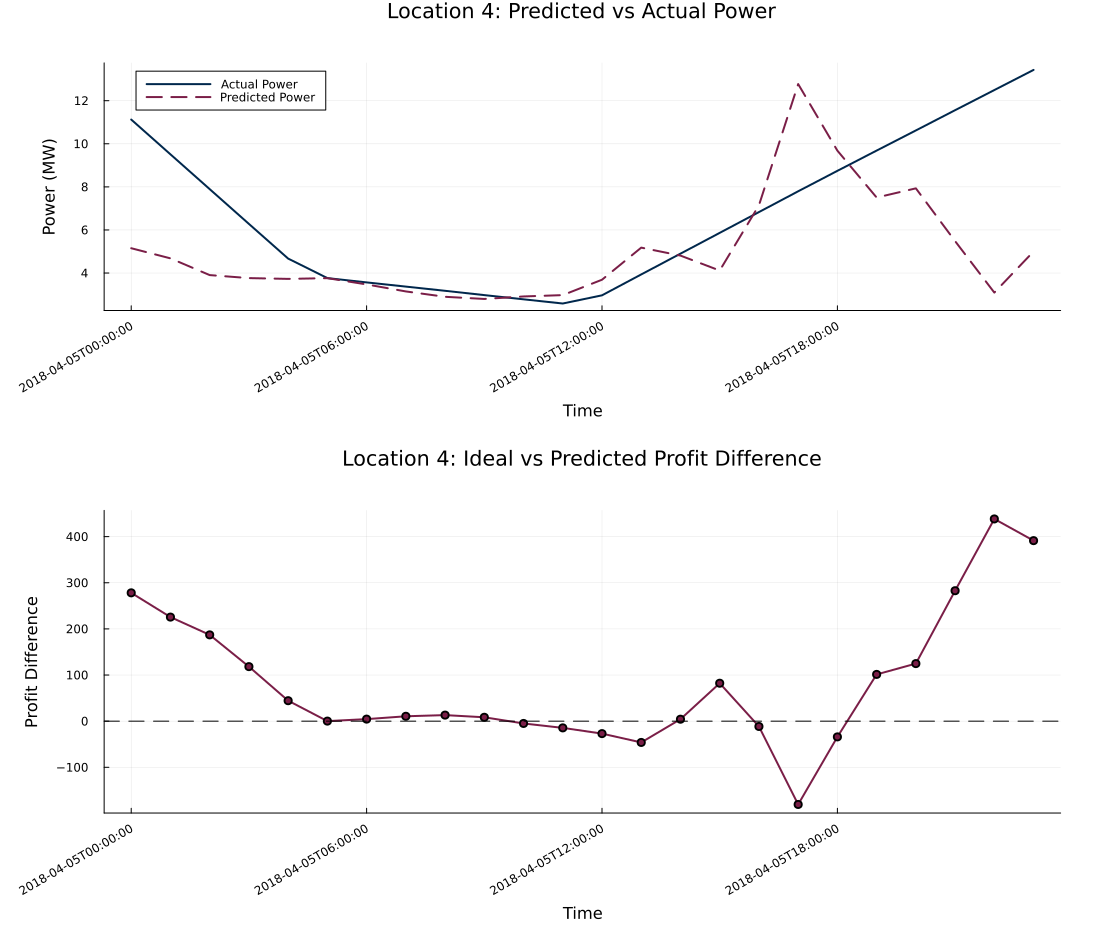

Test-day RMSE (MW): 3.6615849208679947
Total predicted profit: 4848.655504880047
Total ideal-forecast profit: 6844.948316775012
Total profit difference: 1996.2928118949626


In [6]:

function sigmoid(z)
    if z >= 0
        return 1.0 / (1.0 + exp(-z))
    else
        ez = exp(z)
        return ez / (1.0 + ez)
    end
end

Random.seed!(44)

# Load Location 4 as the unseen test location
test_data = CSV.read("Location4.csv", DataFrame)
test_data.Time = DateTime.(test_data.Time)
sort!(test_data, :Time)

# Find complete days containing 24 consecutive hourly observations
test_data.Date = Date.(test_data.Time)
daily_groups = groupby(test_data, :Date)

complete_days = [
    day for day in daily_groups
    if nrow(day) == 24 &&
       length(unique(day.Time)) == 24 &&
       all(diff(sort(day.Time)) .== Hour(1))
]

if isempty(complete_days)
    error("Location 4 contains no complete days with 24 consecutive hourly observations.")
end


test_candidates = []

for day in complete_days
    test_date = day.Date[1]
    previous_date = test_date - Day(1)

    previous_day = filter(
        row -> Date(row.Time) == previous_date,
        test_data
    )

    if nrow(previous_day) == 24 &&
       length(unique(previous_day.Time)) == 24 &&
       all(diff(sort(previous_day.Time)) .== Hour(1))
        push!(test_candidates, day)
    end
end

if isempty(test_candidates)
    error("No test day has a complete preceding day for forecast initialization.")
end

test_day = test_candidates[rand(1:length(test_candidates))]
sort!(test_day, :Time)

previous_date = test_day.Date[1] - Day(1)
previous_day = filter(
    row -> Date(row.Time) == previous_date,
    test_data
)
sort!(previous_day, :Time)

println("Selected test day: ", test_day.Date[1])

# Actual normalized power and previous-day power
t_test = Float64.(test_day.Power)
previous_power = Float64.(previous_day.Power)

# CHANGED: Construct the same weather features used in training
x10_test = Float64.(test_day.windspeed_10m) ./ 10.0
x100_test = Float64.(test_day.windspeed_100m) ./ 10.0
gust_test = Float64.(test_day.windgusts_10m) ./ 10.0

hour_test = Float64.(Dates.hour.(test_day.Time))
hour_sin_test = sin.(2π .* hour_test ./ 24.0)
hour_cos_test = cos.(2π .* hour_test ./ 24.0)

# CHANGED: Match the training RBF feature construction
Φ_weather_test = [
    φ(x10_test[i], j) +
    φ(x100_test[i], j) +
    φ(gust_test[i], j)
    for i in 1:24, j in 1:num_centers
]

Φ_weather_test = hcat(
    Φ_weather_test,
    hour_sin_test,
    hour_cos_test
)

# Recursive 24-hour predictions, including previous power change
prediction_test = zeros(24)

p_lag2 = previous_power[23]
p_lag1 = previous_power[24]

# Previous day's final hourly power change
delta_p_lag1 = p_lag1 - p_lag2

for i in 1:24
    x = vcat(
        Φ_weather_test[i, :],
        p_lag1,
        p_lag2,
        delta_p_lag1
    )

    z = θ[1] + dot(x, θ[2:end])
    prediction_test[i] = sigmoid(z)

    # Update historical values recursively
    p_lag2 = p_lag1
    p_lag1 = prediction_test[i]
    delta_p_lag1 = p_lag1 - p_lag2
end

# Convert normalized power to MW
actual_power = 50.0 .* t_test
predicted_power = 50.0 .* prediction_test

# Calculate hourly profit using the same dispatch functions as training
function calculate_test_profit(forecast_power, actual_power)
    da = solve_nonlinear_economic_dispatch(
        generators,
        wind_generator,
        Scenario(600.0, forecast_power)
    )

    wind_regulation = actual_power - da.w

    rt = solve_realtime_dispatch(
        da.w,
        wind_regulation,
        beta_up_weight,
        beta_down_weight,
        da.alpha,
        da.beta
    )

    return da.wind_revenue - rt.c
end

# Calculate predicted-forecast profit
predicted_profit = [
    calculate_test_profit(predicted_power[i], actual_power[i])
    for i in eachindex(actual_power)
]

# Calculate ideal-forecast profit
ideal_profit = [
    calculate_test_profit(actual_power[i], actual_power[i])
    for i in eachindex(actual_power)
]

# Calculate hourly difference between ideal and predicted profit
profit_difference = ideal_profit .- predicted_profit

# Plot predicted versus actual power
p1 = plot(
    test_day.Time,
    actual_power,
    label = "Actual Power",
    linewidth = 2,
    color = blue,
    xlabel = "Time",
    ylabel = "Power (MW)",
    title = "Location 4: Predicted vs Actual Power",
    legend = :best,
    xrotation = 30
)

plot!(
    p1,
    test_day.Time,
    predicted_power,
    label = "Predicted Power",
    linewidth = 2,
    linestyle = :dash,
    color = purple
)

# Plot profit difference versus time
p2 = plot(
    test_day.Time,
    profit_difference,
    label = "Ideal - Predicted Profit",
    linewidth = 2,
    marker = :circle,
    markersize = 4,
    color = purple,
    xlabel = "Time",
    ylabel = "Profit Difference",
    title = "Location 4: Ideal vs Predicted Profit Difference",
    legend = false,
    xrotation = 30
)

hline!(
    p2,
    [0],
    color = :black,
    linestyle = :dash,
    linewidth = 1,
    label = false
)

# Display both plots explicitly
final_plot = plot(
    p1,
    p2,
    layout = grid(2, 1, heights = [0.45, 0.55]),
    size = (1100, 950),
    margin = 8Plots.mm
)

display(final_plot)

# Optional test metrics
println("Test-day RMSE (MW): ",
    sqrt(mean((predicted_power .- actual_power).^2)))

println("Total predicted profit: ", sum(predicted_profit))
println("Total ideal-forecast profit: ", sum(ideal_profit))
println("Total profit difference: ", sum(profit_difference))
